<a href="https://colab.research.google.com/github/gerardowarbringer-eng/Programacion-para-Analitica-Descrip-Predict/blob/main/271770_%C3%81rbol_de_Decisi%C3%B3n_para_Regresi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ENTREGABLE: Árbol de Decisión para Regresión**



*   ALUMNO: GERARDO ISIDORO REYES
*   MATRÍCULA: 271770



1. Carga y exploración de datos
Cargar el dataset en un DataFrame

Identificar la variable objetivo (MedHouseVal)

Analizar la estructura del dataset (info, describe)

Visualizar la distribución de la variable objetivo

In [33]:
#Importar librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# scikit-learn: preprocesamiento y partición
from sklearn.model_selection import train_test_split

# scikit-learn: árbol de regresión
from sklearn.tree import DecisionTreeRegressor

# scikit-learn: métricas
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


In [34]:
# Cargar los datos
california_data = fetch_california_housing(as_frame=True)

# Cargar el dataset en un DataFrame
df = california_data.frame

# Analizar la estructura del dataset (info, describe)
print("Información del conjunto de datos")
df.info()

print("\nEstadísticas descriptivas")
print(df.describe())

Información del conjunto de datos
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Estadísticas descriptivas
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.

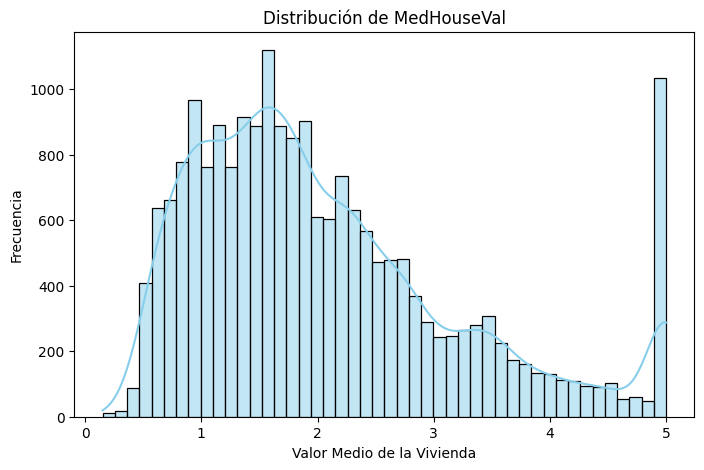

In [35]:
# Visualizar la distribución de la variable "MedHouseVal"
plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], kde=True, color="skyblue")
plt.title("Distribución de MedHouseVal")
plt.xlabel("Valor Medio de la Vivienda")
plt.ylabel("Frecuencia")
plt.show()

* Todas las variables cuentan con 20,640 registros (count = 20640), lo que indica que no hay valores nulos en el dataset

*  **Sesgo a la derecha:** La mayoría de los valores de las viviendas se concentran entre 1.0 y 2.5 ($100,000 USD y $250,000 USD)

* **Censurado superior (Capping):** Hay un pico prominente exactamente en el valor máximo de 5.0 ($500,000 USD) con más de 1,000 observaciones acumuladas ahí. Esto se debe a que el dataset original limitó artificialmente todos los valores mayores o iguales a 5.00001 en esa cifra.


Preparación de datos
Definir:

X: variables predictoras

y: variable objetivo

Dividir los datos en entrenamiento (80%) y prueba (20%)

In [36]:
# X: variables predictoras
X = california_data.data
# y: variable objetivo
y = california_data.target

# Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Tamaño del conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Tamaño del conjunto de prueba (X_test): {X_test.shape}")

Tamaño del conjunto de entrenamiento (X_train): (16512, 8)
Tamaño del conjunto de prueba (X_test): (4128, 8)


3. Modelo base
Entrenar un árbol de decisión sin restricciones (max_depth=None)



*  Evaluar el modelo usando: RMSE y R²
* Comparar desempeño en entrenamiento y prueba
* Determinar si existe sobreajuste



In [37]:
# Entrenar un árbol de decisión sin restricciones (max_depth=None)
tree_base = DecisionTreeRegressor(max_depth=None, random_state=42)
tree_base.fit(X_train, y_train)

# Predicciones
y_train_pred = tree_base.predict(X_train)
y_test_pred = tree_base.predict(X_test)

# Evaluar el modelo usando RMSE y R²
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

# Comparar desempeño en entrenamiento y prueba
print("=== Resultados Modelo Base ===")
print(f"Entrenamiento - RMSE: {rmse_train:.4f} | R²: {r2_train:.4f}")
print(f"Prueba        - RMSE: {rmse_test:.4f} | R²: {r2_test:.4f}")

# Determinar si existe sobreajuste
if rmse_train < rmse_test and r2_train > r2_test:
    print("\nExiste sobreajuste (overfitting): el modelo memorizó el conjunto de entrenamiento.")

=== Resultados Modelo Base ===
Entrenamiento - RMSE: 0.0000 | R²: 1.0000
Prueba        - RMSE: 0.7037 | R²: 0.6221

Existe sobreajuste (overfitting): el modelo memorizó el conjunto de entrenamiento.


4. Análisis Bias–Variance
* Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.
* Graficar el error (RMSE) en entrenamiento y prueba

* Identificar el punto donde el modelo generaliza mejor




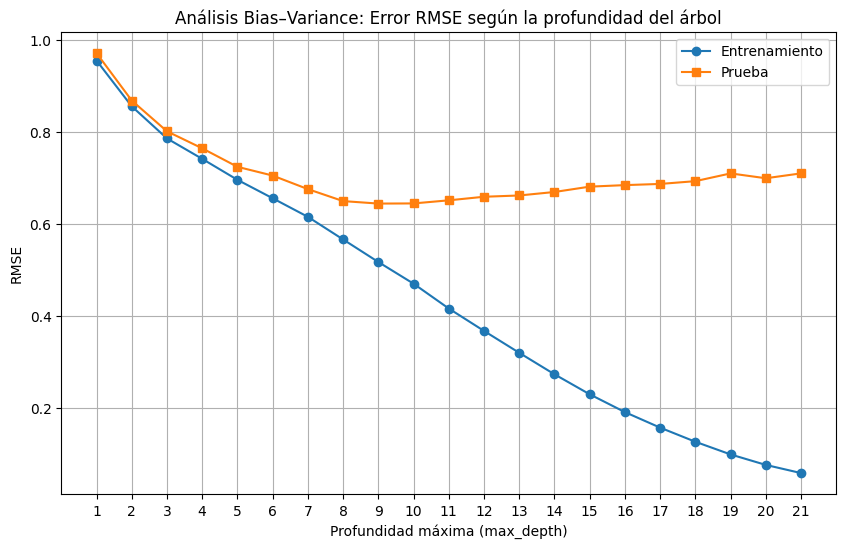

El modelo generaliza mejor a max_depth = 9 con un RMSE de prueba de 0.6443


In [38]:
depths = range(1, 22)
train_rmse_list = []
test_rmse_list = []

# Entrenar múltiples modelos variando max_depth de 1 a 21
for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_rmse_list.append(np.sqrt(mean_squared_error(y_train, pred_train)))
    test_rmse_list.append(np.sqrt(mean_squared_error(y_test, pred_test)))

# Graficar el error (RMSE) en entrenamiento y prueba
plt.figure(figsize=(10, 6))
plt.plot(depths, train_rmse_list, label="Entrenamiento", marker='o')
plt.plot(depths, test_rmse_list, label="Prueba", marker='s')
plt.xlabel("Profundidad máxima (max_depth)")
plt.ylabel("RMSE")
plt.title("Análisis Bias–Variance: Error RMSE según la profundidad del árbol")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

# Identificar el punto donde el modelo generaliza mejor
best_depth = depths[np.argmin(test_rmse_list)]
best_rmse = min(test_rmse_list)
print(f"El modelo generaliza mejor a max_depth = {best_depth} con un RMSE de prueba de {best_rmse:.4f}")

5. Poda del árbol

* Aplicar cost-complexity pruning (ccp_alpha)
* Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]
* Analizar su efecto en el error del modelo


In [ ]:
# Obtener la ruta de poda por complejidad de costos usando un árbol base
tree_temp = DecisionTreeRegressor(random_state=42)
path = tree_temp.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# Se toma una muestra de los alphas para reducir el número de modelos a evaluar
ccp_alphas_subset = ccp_alphas[::5]

train_rmse_list = []
test_rmse_list = []
clfs = []

for ccp_alpha in ccp_alphas_subset:
    clf = DecisionTreeRegressor(random_state=42, ccp_alpha=ccp_alpha)
    clf.fit(X_train, y_train)
    clfs.append(clf)

    # Calcular predicciones y errores (RMSE)
    pred_train = clf.predict(X_train)
    pred_test = clf.predict(X_test)

    train_rmse_list.append(np.sqrt(mean_squared_error(y_train, pred_train)))
    test_rmse_list.append(np.sqrt(mean_squared_error(y_test, pred_test)))

In [ ]:
# 3. Analizar su efecto en el error del modelo
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas_subset, train_rmse_list, marker='o', label="RMSE Entrenamiento", drawstyle="steps-post")
plt.plot(ccp_alphas_subset, test_rmse_list, marker='s', label="RMSE Prueba", drawstyle="steps-post")
plt.xlabel("ccp_alpha")
plt.ylabel("RMSE")
plt.title("Efecto del parámetro ccp_alpha en el error del modelo (Poda del árbol)")
plt.legend()
plt.grid(True)
plt.show()

# Identificar el ccp_alpha con el mejor desempeño en el conjunto de prueba
best_alpha_idx = np.argmin(test_rmse_list)
best_alpha = ccp_alphas_subset[best_alpha_idx]
best_pruned_rmse = test_rmse_list[best_alpha_idx]

print(f"Mejor ccp_alpha: {best_alpha:.6f}")
print(f"RMSE de prueba con el árbol podado: {best_pruned_rmse:.4f}")

6. Interpretación de resultados

*Responder de manera justificada:
* ¿El modelo base presenta sobreajuste? Explique
* ¿Cómo afecta la profundidad del árbol al error?
* ¿Qué efecto tiene la poda en el modelo?
* ¿Cuál configuración produce el mejor desempeño?
* ¿Qué variables son más relevantes según el modelo?
